# **Plant Height and Leaf-count Multivariate Modeling**
Imagine you’re studying two different but related traits in plants:

* Plant Height (measured in centimeters): This is a continuous value that varies smoothly.
* Number of Leaves (a count): This is an integer and can only take whole numbers.

You suspect that these genetic machinary for these two traits are related. Taller plants may naturally have more leaves, and environmental factors like sunlight or water might affect both traits at the same time. You want to build a model that captures both of these traits together to understand:

1. How each factor (like sunlight or water) affects both height and leaf count.
2. How the traits are connected—whether changes in height tend to correspond with changes in leaf count.

Since Python’s `statsmodels` doesn’t directly support this kind of multivariate modeling with mixed data types, we’ll instead fit two separate GLMs; one for height as a continuous outcome and another for leaf count as a count outcome.

By looking at these two models together, we can get a rough idea of how both traits may be effected by the same predictors.

The plan is to:

**Step 1. Create Synthetic Data**

 Simulate predictor variables and two related outcome variables—one continuous (height) and one count (number of leaves).

**Step 2. Fit Two GLMs**

One GLM for height using a Gaussian (normal) distribution.
Another GLM for leaf count using a Poisson distribution.

**Step 3. Analyze Results**

Compare the effects of each predictor on the two traits.



GLM for Plant Height (Gaussian):
                  Generalized Linear Model Regression Results                  
Dep. Variable:                 height   No. Observations:                  200
Model:                            GLM   Df Residuals:                      196
Model Family:                Gaussian   Df Model:                            3
Link Function:               Identity   Scale:                          25.954
Method:                          IRLS   Log-Likelihood:                -607.40
Date:                Mon, 11 Nov 2024   Deviance:                       5086.9
Time:                        17:34:02   Pearson chi2:                 5.09e+03
No. Iterations:                     3   Pseudo R-squ. (CS):             0.7578
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     49.7

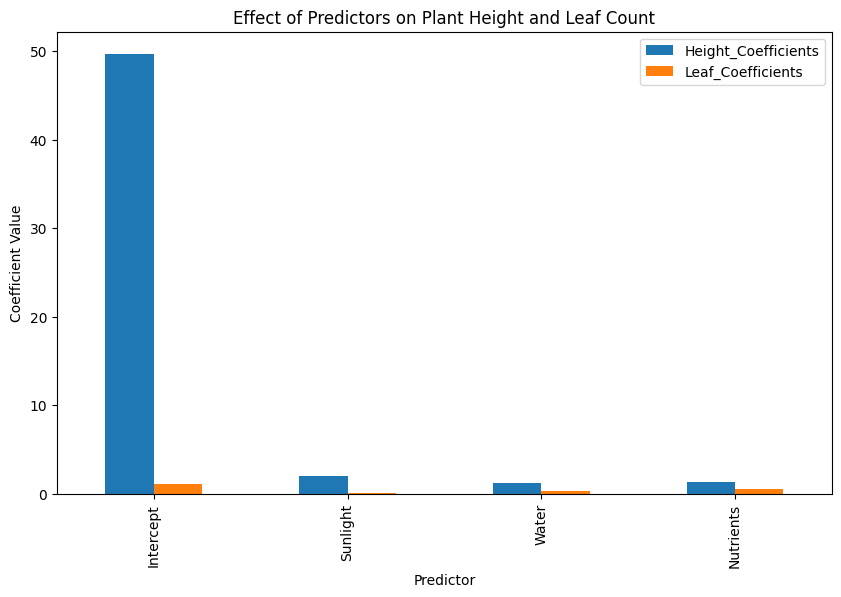

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Step 1: Generate synthetic data for predictors and two related traits
np.random.seed(42)
n_samples = 200

# Simulating Predictor variables
sunlight = np.random.rand(n_samples) * 10  # Hours of sunlight per day
water = np.random.rand(n_samples) * 5      # Liters of water per day
nutrients = np.random.rand(n_samples) * 3  # Nutrient concentration (arbitrary units)

# Response variable 1: Plant Height (Continuous)
height = 50 + 2 * sunlight + 1.5 * water + 0.8 * nutrients + np.random.normal(0, 5, n_samples)

# Response variable 2: Number of Leaves (Count)
leaves = np.random.poisson(lam=np.exp(1 + 0.1 * sunlight + 0.3 * water + 0.5 * nutrients))

# Combine into a DataFrame
data = pd.DataFrame({
    "sunlight": sunlight,
    "water": water,
    "nutrients": nutrients,
    "height": height,
    "leaves": leaves
})

# Add intercept for GLM fitting
data["Intercept"] = 1

# Step 2: Fit separate GLMs for each response variable

# GLM for Plant Height (Gaussian distribution, Identity link)
glm_height = sm.GLM(data["height"], data[["Intercept", "sunlight", "water", "nutrients"]],
                    family=sm.families.Gaussian()).fit()

# GLM for Number of Leaves (Poisson distribution, Log link)
glm_leaves = sm.GLM(data["leaves"], data[["Intercept", "sunlight", "water", "nutrients"]],
                    family=sm.families.Poisson()).fit()

# Step 3: Summarize and interpret results
print("GLM for Plant Height (Gaussian):\n", glm_height.summary())
print("\nGLM for Number of Leaves (Poisson):\n", glm_leaves.summary())

# Step 4 (optional): Compare coefficients visually
import matplotlib.pyplot as plt

# Coefficients for each predictor from both models
coeffs = pd.DataFrame({
    "Predictor": ["Intercept", "Sunlight", "Water", "Nutrients"],
    "Height_Coefficients": glm_height.params,
    "Leaf_Coefficients": glm_leaves.params
})

# Plot coefficients for comparison
coeffs.plot(x="Predictor", kind="bar", figsize=(10, 6), legend=True)
plt.title("Effect of Predictors on Plant Height and Leaf Count")
plt.ylabel("Coefficient Value")
plt.show()


The real values are:
```
# Response variable 1: Plant Height (Continuous)
height = 50 +
  2 * sunlight +
  1.5 * water +
  0.8 * nutrients +
  np.random.normal(0, 5, n_samples)

# Response variable 2: Modified Leaf Count (Treated as Continuous for SUR)
leaf_count_continuous = 10 +
  1.2 * sunlight +
  1.8 * water +
  1.1 * nutrients +
  np.random.normal(0, 3, n_samples)
```

Alternately- we can treat the `leaf-count` data as continous and try to use SUR approach

In [ ]:
!pip install linearmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.5/94.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
from linearmodels.system import SUR

# Step 1: Generate synthetic data for predictors and two related traits
np.random.seed(42)
n_samples = 200

# Predictor variables
sunlight = np.random.rand(n_samples) * 10  # Hours of sunlight per day
water = np.random.rand(n_samples) * 5      # Liters of water per day
nutrients = np.random.rand(n_samples) * 3  # Nutrient concentration (arbitrary units)

# Response variable 1: Plant Height (Continuous)
height = 50 + 2 * sunlight + 1.5 * water + 0.8 * nutrients + np.random.normal(0, 5, n_samples)

# Response variable 2: Modified Leaf Count (Treated as Continuous for SUR)
leaf_count_continuous = 10 + 1.2 * sunlight + 1.8 * water + 1.1 * nutrients + np.random.normal(0, 3, n_samples)

# Combine into a DataFrame
data = pd.DataFrame({
    "sunlight": sunlight,
    "water": water,
    "nutrients": nutrients,
    "height": height,
    "leaf_count_continuous": leaf_count_continuous
})

# Step 2: Define the equations using the formula interface in linearmodels

# Each equation is specified as a string formula
equations = {
    'height': 'height ~ sunlight + water + nutrients',
    'leaf_count_continuous': 'leaf_count_continuous ~ sunlight + water + nutrients'
}

# Step 3: Fit the SUR model
# We use the from_formula method and pass the equations dictionary along with the data
sur_model = SUR.from_formula(equations, data)
sur_results = sur_model.fit()

# Display results
print(sur_results.summary)


                           System GLS Estimation Summary                           
Estimator:                        GLS   Overall R-squared:                   0.9429
No. Equations.:                     2   McElroy's R-squared:                 0.1473
No. Observations:                 200   Judge's (OLS) R-squared:            -2.0829
Date:                Mon, Nov 11 2024   Berndt's R-squared:                 -1.2660
Time:                        18:06:46   Dhrymes's R-squared:                 0.9474
                                        Cov. Estimator:                      robust
                                        Num. Constraints:                      None
                 Equation: height, Dependent Variable: height                 
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
sunlight       4.7594     0.2979     15.978     0.0000      4.1756      5.3433
water       

The real values are:
```
# Response variable 1: Plant Height (Continuous)
height = 50 +
  2 * sunlight +
  1.5 * water +
  0.8 * nutrients +
  np.random.normal(0, 5, n_samples)

# Response variable 2: Modified Leaf Count (Treated as Continuous for SUR)
leaf_count_continuous = 10 +
  1.2 * sunlight +
  1.8 * water +
  1.1 * nutrients +
  np.random.normal(0, 3, n_samples)
```
